# 09 - Image-only and fusion models



## 1. Imports and settings



In [1]:
import random
import hashlib
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import roc_curve, confusion_matrix, f1_score

project_folder = Path(r"E:\ADS2002_Melanoma")
data_folder = project_folder / "data" / "Melanoma-Kaggle-Subset"

split_level = "patient"
# both models use the same folds and training settings
folds = 3
seed = 42
image_size = 224
batch_size = 32
epochs = 15
frozen_epochs = 2
patience = 4
head_learning_rate = 0.0003
image_learning_rate = 0.00002
weight_decay = 0.0001
target_sensitivity = 0.90

results_folder = project_folder / "results" / "three_fold_comparison" / split_level
results_folder.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Results:", results_folder)

Device: cuda
GPU: NVIDIA GeForce RTX 4090
Results: E:\ADS2002_Melanoma\results\three_fold_comparison\patient


In [2]:
def set_seed(number):
    random.seed(number)
    np.random.seed(number)
    torch.manual_seed(number)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(number)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(seed)

## 2. Read the subset and check it



In [3]:
train_df = pd.read_csv(data_folder / "train_labels.csv")
test_df = pd.read_csv(data_folder / "test_labels.csv")

needed = ["image_name", "patient_id", "target", "age_approx",
          "sex", "anatom_site_general_challenge"]

for table in [train_df, test_df]:
    if not set(needed).issubset(table.columns):
        raise ValueError("Some required columns are missing.")
    if table["image_name"].isna().any() or table["patient_id"].isna().any():
        raise ValueError("Image names and patient IDs must not be missing.")
    if not table["image_name"].is_unique:
        raise ValueError("Image names must be unique in each label file.")
    if set(table["target"].unique()) != {0, 1}:
        raise ValueError("The target column must contain both 0 and 1.")

shared_patients = set(train_df["patient_id"]) & set(test_df["patient_id"])
if shared_patients:
    raise ValueError("Training and test patients overlap. Check the dataset first.")

print("Training images:", len(train_df))
print("Test images:", len(test_df))
display(train_df["target"].value_counts().sort_index())

Training images: 6864
Test images: 1988


target
0    6736
1     128
Name: count, dtype: int64

## 3. Remove duplicates before making folds



In [ ]:
def image_hashes(table, folder):
    hashes = []
    for i in range(len(table)):
        image_path = folder / (str(table.iloc[i]["image_name"]) + ".jpg")
        with open(image_path, "rb") as image_file:
            value = hashlib.sha256(image_file.read()).hexdigest()
        hashes.append(value)
        if (i + 1) % 1000 == 0:
            print("Checked", i + 1, "images in", folder.name)
    return hashes





train_df["image_hash"] = image_hashes(train_df, data_folder / "train")
test_df["image_hash"] = image_hashes(test_df, data_folder / "test")
original_train_df = train_df.copy()
original_test_df = test_df.copy()

duplicate_sets = []
all_images = pd.concat([train_df, test_df])
for _, rows in all_images.groupby("image_hash"):
    if rows["image_name"].nunique() > 1:
        duplicate_sets.append(set(rows["image_name"]))

duplicate_file = project_folder / "data" / "raw" / "ISIC_2020_Training_Duplicates.csv"
if duplicate_file.exists():
    duplicate_pairs = pd.read_csv(duplicate_file)
    for i in range(len(duplicate_pairs)):
        pair = duplicate_pairs.iloc[i]
        duplicate_sets.append({pair["image_name_1"], pair["image_name_2"]})
else:
    print("ISIC duplicate list not found; only exact file matches can be removed.")

# merge connected pairs, including links through photos outside this subset
duplicate_groups = []
for group in duplicate_sets:
    separate_groups = []
    for old_group in duplicate_groups:
        if group & old_group:
            group = group | old_group
        else:
            separate_groups.append(old_group)
    separate_groups.append(group)
    duplicate_groups = separate_groups




conflicting = train_df.groupby("image_hash")["target"].nunique()
if (conflicting > 1).any():
    raise ValueError("Identical training files have different labels.")
conflicting = test_df.groupby("image_hash")["target"].nunique()
if (conflicting > 1).any():
    raise ValueError("Identical test files have different labels.")

before = len(test_df)
test_df = test_df.sort_values("image_name").drop_duplicates("image_hash").copy()
print("Exact test duplicates excluded:", before - len(test_df))

before = len(train_df)
train_df = train_df.sort_values("image_name").drop_duplicates("image_hash").copy()
print("Exact training duplicates removed:", before - len(train_df))

before = len(train_df)
train_df = train_df[~train_df["image_hash"].isin(test_df["image_hash"])].copy()
print("Training copies of test images removed:", before - len(train_df))





excluded_names = set()
excluded_test_names = set()
test_names = set(test_df["image_name"])
for group in duplicate_groups:
    members = train_df[train_df["image_name"].isin(group)]
    test_members = test_df[test_df["image_name"].isin(group)]
    if members["target"].nunique() > 1:
        raise ValueError("A known duplicate group has conflicting training labels.")
    if test_members["target"].nunique() > 1:
        raise ValueError("A known duplicate group has conflicting test labels.")
    member_names = sorted(members["image_name"])
    excluded_test_names.update(sorted(test_members["image_name"])[1:])
    if group & test_names:
        excluded_names.update(member_names)
    else:
        excluded_names.update(member_names[1:])







before = len(train_df)
train_df = train_df[~train_df["image_name"].isin(excluded_names)].copy()
print("Additional known duplicate training photos removed:", before - len(train_df))
before = len(test_df)
test_df = test_df[~test_df["image_name"].isin(excluded_test_names)].copy()
print("Additional known duplicate test photos excluded:", before - len(test_df))
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
excluded = original_train_df[~original_train_df["image_name"].isin(train_df["image_name"])]
excluded.to_csv(results_folder / "excluded_training_duplicates.csv", index=False)
excluded = original_test_df[~original_test_df["image_name"].isin(test_df["image_name"])]
excluded.to_csv(results_folder / "excluded_test_duplicates.csv", index=False)
print("Training images remaining:", len(train_df))
print("Test images remaining:", len(test_df))

Checked 1000 images in train
Checked 2000 images in train
Checked 3000 images in train
Checked 4000 images in train
Checked 5000 images in train
Checked 6000 images in train
Checked 1000 images in test
Exact test duplicates excluded: 2
Exact training duplicates removed: 158
Training copies of test images removed: 0
Additional known duplicate training photos removed: 0
Additional known duplicate test photos excluded: 0
Training images remaining: 6706
Test images remaining: 1986


## 4. Make the same three folds for both models

In each run, two folds train the model and the remaining fold validates it.
Every training image is used for validation once. With patient splitting,
patients are stratified by whether they have at least one melanoma image.

In [5]:
splitter = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed)
train_df["fold"] = -1

if split_level == "patient":
    patients = train_df.groupby("patient_id", as_index=False)["target"].max()
    for fold, (_, validation_index) in enumerate(splitter.split(patients, patients["target"])):
        validation_patients = patients.iloc[validation_index]["patient_id"]
        train_df.loc[train_df["patient_id"].isin(validation_patients), "fold"] = fold
elif split_level == "image":
    for fold, (_, validation_index) in enumerate(splitter.split(train_df, train_df["target"])):
        train_df.loc[validation_index, "fold"] = fold
else:
    raise ValueError("split_level must be patient or image")

assert (train_df["fold"] >= 0).all()
if split_level == "patient":
    assert train_df.groupby("patient_id")["fold"].nunique().max() == 1

for fold in range(folds):
    if train_df.loc[train_df["fold"] == fold, "target"].nunique() != 2:
        raise ValueError("Each validation fold needs both classes.")

display(pd.crosstab(train_df["fold"] + 1, train_df["target"]))
train_df[["image_name", "patient_id", "target", "fold"]].to_csv(
    results_folder / "fold_assignments.csv", index=False)

target,0,1
fold,,
1,2096,40
2,2184,44
3,2299,43


## 5. Prepare age, sex and body site

Each fold fits its median, age scaler and category encoder using only its
training rows. The same fitted objects transform validation and test rows.
Diagnosis and patient ID are excluded from the predictors.

In [6]:
category_columns = ["sex", "anatom_site_general_challenge"]

def prepare_metadata(table, age_median, age_scaler, encoder):
    age = pd.to_numeric(table["age_approx"], errors="coerce")
    missing_age = age.isna().to_numpy(dtype=np.float32).reshape(-1, 1)
    age_values = age.fillna(age_median).to_numpy().reshape(-1, 1)
    scaled_age = age_scaler.transform(age_values)
    categories = table[category_columns].fillna("missing").astype(str)
    encoded_categories = encoder.transform(categories)
    return np.concatenate([scaled_age, missing_age, encoded_categories], axis=1).astype(np.float32)

def fit_metadata(table):
    age = pd.to_numeric(table["age_approx"], errors="coerce")
    age_median = age.median()
    if pd.isna(age_median):
        raise ValueError("All training ages are missing.")
    age_scaler = StandardScaler()
    age_scaler.fit(age.fillna(age_median).to_numpy().reshape(-1, 1))
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    encoder.fit(table[category_columns].fillna("missing").astype(str))
    return age_median, age_scaler, encoder

## 6. Prepare images and batches

Small crops, flips and rotations give training images some variety.
Colour changes are mild because lesion colour can matter. Validation and
test use the same fixed transformations, without random changes or flip averaging.
ImageNet normalisation matches the pretrained EfficientNet weights.

In [7]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(image_size, scale=(0.90, 1.00), ratio=(0.95, 1.05)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

evaluation_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(image_size),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

class MelanomaDataset(Dataset):
    def __init__(self, table, metadata, folder, transform):
        self.table = table.reset_index(drop=True)
        self.metadata = torch.tensor(metadata, dtype=torch.float32)
        self.folder = folder
        self.transform = transform

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        path = self.folder / (str(row["image_name"]) + ".jpg")
        with Image.open(path) as opened_image:
            image = opened_image.convert("RGB")
        image = self.transform(image)
        target = torch.tensor(float(row["target"]), dtype=torch.float32)
        return image, self.metadata[index], target

def make_loader(table, metadata, folder, transform, shuffle, run_seed):
    dataset = MelanomaDataset(table, metadata, folder, transform)
    generator = torch.Generator().manual_seed(run_seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=0, generator=generator)

## 7. Build image-only and fusion models

Both start from the same ImageNet-pretrained EfficientNet-B0. The image-only
model uses its 1,280 image features. Fusion also adds 16 learned metadata
features. The final classifier has 64 hidden units and dropout of 0.4.
The smaller head and metadata branch aim to reduce overfitting on this small subset.
(will try B3 and resnet18 later for comparison)

In [8]:
class MelanomaModel(nn.Module):
    def __init__(self, metadata_size, use_metadata):
        super().__init__()
        backbone = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
        self.features = backbone.features
        self.pool = backbone.avgpool
        self.use_metadata = use_metadata
        feature_count = backbone.classifier[1].in_features

        if use_metadata:
            self.metadata_branch = nn.Sequential(
                nn.Linear(metadata_size, 16), nn.ReLU(), nn.Dropout(0.2))
            feature_count = feature_count + 16

        self.classifier = nn.Sequential(
            nn.Linear(feature_count, 64), nn.ReLU(),
            nn.Dropout(0.4), nn.Linear(64, 1))

        for parameter in self.features.parameters():
            parameter.requires_grad = False

    def forward(self, images, metadata):
        image_features = self.pool(self.features(images)).flatten(1)
        if self.use_metadata:
            metadata_features = self.metadata_branch(metadata)
            image_features = torch.cat([image_features, metadata_features], dim=1)
        return self.classifier(image_features).squeeze(1)

## 8. Measure performance and choose a threshold


In [9]:
def predict(model, loader):
    model.eval()
    probabilities = []
    with torch.no_grad():
        for images, metadata, targets in loader:
            outputs = model(images.to(device), metadata.to(device))
            probabilities.extend(torch.sigmoid(outputs).cpu().numpy())
    return np.array(probabilities)

def choose_threshold(targets, probabilities):
    false_positive_rate, sensitivity, thresholds = roc_curve(targets, probabilities)
    valid = np.isfinite(thresholds) & (sensitivity >= target_sensitivity)
    choices = np.where(valid)[0]
    best = choices[np.argmin(false_positive_rate[choices])]
    return float(thresholds[best])

def measure(targets, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(targets, predictions, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    return {
        "roc_auc": roc_auc_score(targets, probabilities),
        "pr_auc": average_precision_score(targets, probabilities),
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": tp / max(tp + fp, 1),
        "f1": f1_score(targets, predictions, zero_division=0),
        "balanced_accuracy": (sensitivity + specificity) / 2,
        "true_positive": int(tp), "false_negative": int(fn),
        "false_positive": int(fp), "true_negative": int(tn)
    }

## 9. Train one model

The first two epochs train the new layers. Then only the last two EfficientNet
blocks are unfrozen, with a smaller learning rate. Batch-normalisation running
statistics stay fixed to avoid large changes from this small dataset.

Weighted binary cross-entropy uses the square root of the benign/melanoma
ratio. This increases the importance of melanoma without using the full
imbalance ratio. AdamW uses weight decay of 0.0001. The learning rate halves
after a validation PR-AUC plateau, and early stopping has patience 4.

In [ ]:
def train_model(model, train_loader, validation_loader, validation_targets,
                positive_weight, model_path, history_path):
    loss_function = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor([positive_weight], dtype=torch.float32, device=device))

    groups = [
        {"params": model.features.parameters(), "lr": image_learning_rate},
        {"params": model.classifier.parameters(), "lr": head_learning_rate}
    ]
    if model.use_metadata:
        groups.append({"params": model.metadata_branch.parameters(),
                       "lr": head_learning_rate})





    optimizer = torch.optim.AdamW(groups, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=1)
    best_score = -1
    best_epoch = 0
    waiting = 0
    history = []





    for epoch in range(1, epochs + 1):
        start = time.time()
        if epoch == frozen_epochs + 1:
            for parameter in model.features[-2:].parameters():
                parameter.requires_grad = True
            waiting = 0
            print("Fine-tuning the last two image blocks")

        model.train()
        model.features.eval()  # keep batch-normalisation statistics fixed
        total_loss = 0
        total_images = 0

        for images, metadata, targets in train_loader:
            images = images.to(device)
            metadata = metadata.to(device)
            targets = targets.to(device)
            optimizer.zero_grad()
            outputs = model(images, metadata)
            loss = loss_function(outputs, targets)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss = total_loss + loss.item() * len(targets)
            total_images = total_images + len(targets)

        probabilities = predict(model, validation_loader)
        validation_pr = average_precision_score(validation_targets, probabilities)
        validation_roc = roc_auc_score(validation_targets, probabilities)
        scheduler.step(validation_pr)
        history.append({"epoch": epoch, "training_loss": total_loss / total_images,
                        "validation_pr_auc": validation_pr,
                        "validation_roc_auc": validation_roc})
        print("Epoch", epoch, "loss", round(total_loss / total_images, 4),
              "validation PR-AUC", round(validation_pr, 4),
              "minutes", round((time.time() - start) / 60, 2))

        if validation_pr > best_score + 0.0001:
            best_score = validation_pr
            best_epoch = epoch
            waiting = 0
            torch.save(model.state_dict(), model_path)
        else:
            waiting = waiting + 1

        pd.DataFrame(history).to_csv(history_path, index=False)
        if epoch > frozen_epochs and waiting >= patience:
            print("Early stopping")
            break

    model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
    return best_epoch

## 10. Run all three folds

This is the long-running cell. It trains six models and saves each best
checkpoint. Each run starts fresh from ImageNet weights, rather than
continuing from the previous fold. Images are shuffled each training epoch.

Validation data select the epoch and threshold, so these validation scores
can be optimistic. The later held-out test comparison is the independent
check for this experiment. Use the results to assess changes, not assume
that the new models will beat the old ones.

In [ ]:
validation_rows = []
validation_prediction_rows = []





for fold in range(folds):
    development = train_df[train_df["fold"] != fold].reset_index(drop=True)
    validation = train_df[train_df["fold"] == fold].reset_index(drop=True)

    preprocessing = fit_metadata(development)
    joblib.dump(preprocessing, results_folder / ("metadata_fold_" + str(fold + 1) + ".joblib"))
    train_metadata = prepare_metadata(development, *preprocessing)
    validation_metadata = prepare_metadata(validation, *preprocessing)
    positive_count = int(development["target"].sum())
    # square-root weighting helps rare melanoma examples without the full class ratio
    positive_weight = ((len(development) - positive_count) / positive_count) ** 0.5









    for model_name in ["image_only", "fusion"]:
        print()
        print("Fold", fold + 1, "-", model_name)
        print("Training:", len(development), "Validation:", len(validation))
        set_seed(seed + fold)
        train_loader = make_loader(development, train_metadata, data_folder / "train",
                                   train_transform, True, seed + fold)
        validation_loader = make_loader(validation, validation_metadata, data_folder / "train",
                                        evaluation_transform, False, seed + fold)
        model = MelanomaModel(train_metadata.shape[1], model_name == "fusion").to(device)
        name = model_name + "_fold_" + str(fold + 1)
        model_path = results_folder / (name + ".pth")

        best_epoch = train_model(model, train_loader, validation_loader,
                                 validation["target"].to_numpy(), positive_weight,
                                 model_path, results_folder / (name + "_history.csv"))

        probabilities = predict(model, validation_loader)
        # choose the threshold from validation data only
        threshold = choose_threshold(validation["target"].to_numpy(), probabilities)
        scores = measure(validation["target"].to_numpy(), probabilities, threshold)
        scores.update({"model": model_name, "fold": fold + 1, "best_epoch": best_epoch,
                       "threshold": threshold, "metadata_size": train_metadata.shape[1],
                       "positive_weight": positive_weight})
        validation_rows.append(scores)

        predictions = validation[["image_name", "patient_id", "target"]].copy()
        predictions["model"] = model_name
        predictions["fold"] = fold + 1
        predictions["probability"] = probabilities
        predictions["prediction"] = (probabilities >= threshold).astype(int)
        validation_prediction_rows.append(predictions)

        pd.DataFrame(validation_rows).to_csv(results_folder / "validation_results.csv", index=False)
        pd.concat(validation_prediction_rows).to_csv(
            results_folder / "validation_predictions.csv", index=False)
        print("Best epoch:", best_epoch, "Threshold:", round(threshold, 6))
        del model, train_loader, validation_loader
        if device.type == "cuda":
            torch.cuda.empty_cache()

validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))


Fold 1 - image_only
Training: 4570 Validation: 2136
Epoch 1 loss 0.47 validation PR-AUC 0.0618 minutes 0.52
Epoch 2 loss 0.4014 validation PR-AUC 0.0817 minutes 0.52
Fine-tuning the last two image blocks
Epoch 3 loss 0.4205 validation PR-AUC 0.1017 minutes 0.52
Epoch 4 loss 0.4565 validation PR-AUC 0.1133 minutes 0.51
Epoch 5 loss 0.4356 validation PR-AUC 0.1215 minutes 0.51
Epoch 6 loss 0.405 validation PR-AUC 0.1321 minutes 0.52
Epoch 7 loss 0.3839 validation PR-AUC 0.1314 minutes 0.56
Epoch 8 loss 0.3976 validation PR-AUC 0.1257 minutes 0.62
Epoch 9 loss 0.3418 validation PR-AUC 0.1239 minutes 0.59
Epoch 10 loss 0.3645 validation PR-AUC 0.1196 minutes 0.51
Early stopping
Best epoch: 6 Threshold: 0.009034

Fold 1 - fusion
Training: 4570 Validation: 2136
Epoch 1 loss 0.4722 validation PR-AUC 0.0714 minutes 0.5
Epoch 2 loss 0.4055 validation PR-AUC 0.1004 minutes 0.51
Fine-tuning the last two image blocks
Epoch 3 loss 0.3891 validation PR-AUC 0.1164 minutes 0.51
Epoch 4 loss 0.4411 va

,roc_auc,pr_auc,sensitivity,specificity,precision,f1,balanced_accuracy,true_positive,false_negative,false_positive,true_negative,model,fold,best_epoch,threshold,metadata_size,positive_weight
0,0.8261,0.1321,0.9000,0.5000,0.0332,0.0641,0.7000,36,4,1048,1048,image_only,1,6,0.0090,11,7.1784
1,0.8233,0.1500,0.9000,0.5000,0.0332,0.0641,0.7000,36,4,1048,1048,fusion,1,15,0.0034,11,7.1784
2,0.7956,0.0815,0.9091,0.5119,0.0362,0.0696,0.7105,40,4,1066,1118,image_only,2,13,0.0032,11,7.2768
3,0.8023,0.0862,0.9091,0.5467,0.0388,0.0745,0.7279,40,4,990,1194,fusion,2,8,0.0024,11,7.2768
4,0.7386,0.1163,0.9070,0.3432,0.0252,0.0490,0.6251,39,4,1510,789,image_only,3,6,0.0024,11,7.1381
5,0.7506,0.1236,0.9070,0.3149,0.0242,0.0471,0.6109,39,4,1575,724,fusion,3,6,0.0022,11,7.1381


## 11. Compare validation performance

The table shows mean and standard deviation over three folds. Standard
deviation describes variation between folds; it is not a confidence interval.
Positive fusion-minus-image differences mean fusion has the higher score.

roc_auc          pr_auc         sensitivity         specificity  \
              mean     std    mean     std        mean     std        mean   
model                                                                        
fusion      0.7921  0.0374  0.1199  0.0321      0.9054  0.0048      0.4539   
image_only  0.7868  0.0444  0.1100  0.0259      0.9054  0.0048      0.4517   

                   precision         balanced_accuracy         false_negative  \
               std      mean     std              mean     std           mean   
model                                                                           
fusion      0.1226    0.0321  0.0074            0.6796  0.0611            4.0   
image_only  0.0942    0.0315  0.0057            0.6785  0.0466            4.0   

                false_positive            
            std           mean       std  
model                                     
fusion      0.0      1204.3333  322.3140  
image_only  0.0      1208.0000  261.6945

model,fusion,image_only,fusion_minus_image
fold,,,
1,0.1500,0.1321,0.0179
2,0.0862,0.0815,0.0046
3,0.1236,0.1163,0.0073


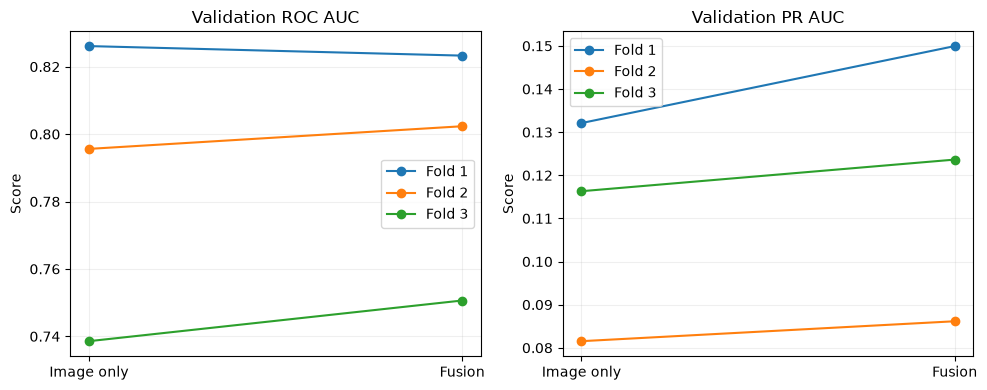

In [ ]:
score_columns = ["roc_auc", "pr_auc", "sensitivity", "specificity",
                 "precision", "balanced_accuracy", "false_negative", "false_positive"]
validation_results = pd.read_csv(results_folder / "validation_results.csv")
validation_summary = validation_results.groupby("model")[score_columns].agg(["mean", "std"])
display(validation_summary.round(4))
validation_summary.to_csv(results_folder / "validation_summary.csv")




validation_pairs = validation_results.pivot(index="fold", columns="model", values="pr_auc")
validation_pairs["fusion_minus_image"] = validation_pairs["fusion"] - validation_pairs["image_only"]
display(validation_pairs.round(4))
validation_pairs.to_csv(results_folder / "paired_validation_pr_auc.csv")





figure, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, metric in zip(axes, ["roc_auc", "pr_auc"]):
    pairs = validation_results.pivot(index="fold", columns="model", values=metric)
    for fold in pairs.index:
        axis.plot([0, 1], [pairs.loc[fold, "image_only"], pairs.loc[fold, "fusion"]],
                  marker="o", label="Fold " + str(fold))
    axis.set_xticks([0, 1], ["Image only", "Fusion"])
    axis.set_title("Validation " + metric.replace("_", " ").upper())
    axis.set_ylabel("Score")
    axis.legend()
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(results_folder / "validation_comparison.png", dpi=160)
plt.show()

## 12. Compare all six models on the same test set



In [ ]:
test_rows = []
test_prediction_rows = []




for i in range(len(validation_results)):
    row = validation_results.iloc[i]
    fold = int(row["fold"])
    model_name = row["model"]
    name = model_name + "_fold_" + str(fold)
    preprocessing = joblib.load(results_folder / ("metadata_fold_" + str(fold) + ".joblib"))
    metadata = prepare_metadata(test_df, *preprocessing)
    test_loader = make_loader(test_df, metadata, data_folder / "test",
                              evaluation_transform, False, seed)
    model = MelanomaModel(metadata.shape[1], model_name == "fusion").to(device)
    model.load_state_dict(torch.load(results_folder / (name + ".pth"),
                                    map_location=device, weights_only=True))
    probabilities = predict(model, test_loader)
    threshold = float(row["threshold"])
    scores = measure(test_df["target"].to_numpy(), probabilities, threshold)
    scores.update({"model": model_name, "fold": fold, "threshold": threshold})
    test_rows.append(scores)

    predictions = test_df[["image_name", "patient_id", "target"]].copy()
    predictions["model"] = model_name
    predictions["fold"] = fold
    predictions["probability"] = probabilities
    predictions["prediction"] = (probabilities >= threshold).astype(int)
    test_prediction_rows.append(predictions)
    del model, test_loader
    if device.type == "cuda":
        torch.cuda.empty_cache()







test_results = pd.DataFrame(test_rows)
test_results.to_csv(results_folder / "test_results.csv", index=False)
pd.concat(test_prediction_rows).to_csv(results_folder / "test_predictions.csv", index=False)
display(test_results.round(4))

test_summary = test_results.groupby("model")[score_columns].agg(["mean", "std"])
display(test_summary.round(4))
test_summary.to_csv(results_folder / "test_summary.csv")

,roc_auc,pr_auc,sensitivity,specificity,precision,f1,balanced_accuracy,true_positive,false_negative,false_positive,true_negative,model,fold,threshold
0,0.8167,0.0863,0.9355,0.5253,0.0303,0.0587,0.7304,29,2,928,1027,image_only,1,0.0090
1,0.7832,0.0786,0.8065,0.5703,0.0289,0.0558,0.6884,25,6,840,1115,fusion,1,0.0034
2,0.8029,0.1142,0.8065,0.5402,0.0271,0.0524,0.6733,25,6,899,1056,image_only,2,0.0032
3,0.8158,0.1258,0.8065,0.5857,0.0299,0.0577,0.6961,25,6,810,1145,fusion,2,0.0024
4,0.7967,0.1115,0.9032,0.2977,0.0200,0.0391,0.6005,28,3,1373,582,image_only,3,0.0024
5,0.8063,0.1146,0.9355,0.2731,0.0200,0.0392,0.6043,29,2,1421,534,fusion,3,0.0022


roc_auc          pr_auc         sensitivity         specificity  \
              mean     std    mean     std        mean     std        mean   
model                                                                        
fusion      0.8018  0.0168  0.1063  0.0247      0.8495  0.0745      0.4764   
image_only  0.8054  0.0103  0.1040  0.0154      0.8817  0.0672      0.4544   

                   precision         balanced_accuracy         false_negative  \
               std      mean     std              mean     std           mean   
model                                                                           
fusion      0.1762    0.0263  0.0055            0.6629  0.0509         4.6667   
image_only  0.1359    0.0258  0.0053            0.6681  0.0651         3.6667   

                   false_positive            
               std           mean       std  
model                                        
fusion      2.3094      1023.6667  344.4275  
image_only  2.0817      1066.6667  265.6884

## 13. Plot the before/after comparison


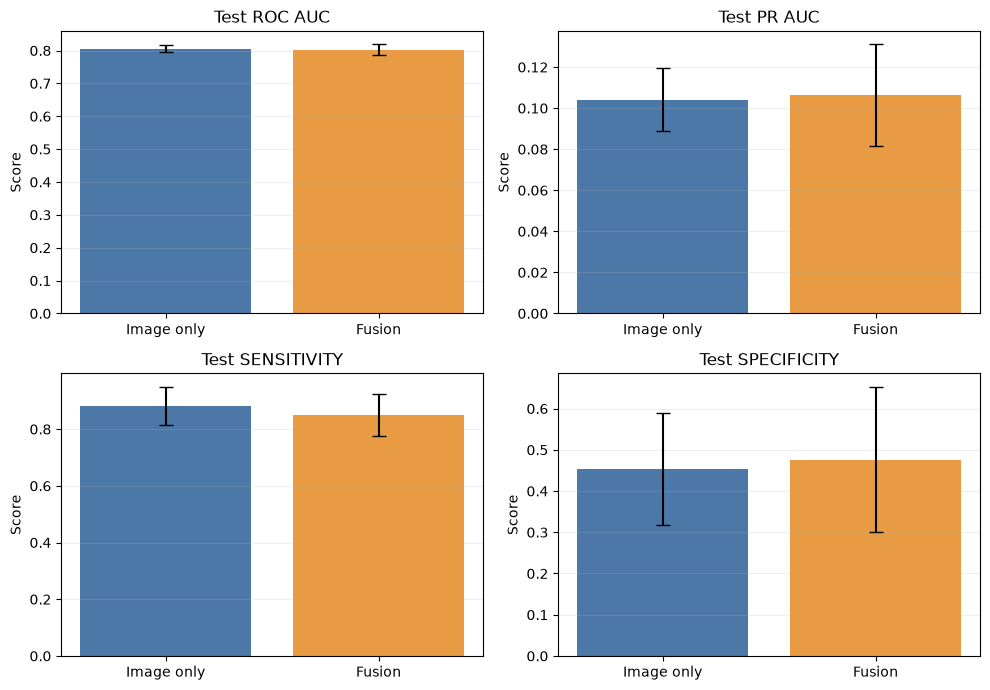

model,fusion,image_only,fusion_minus_image
fold,,,
1,0.0786,0.0863,-0.0078
2,0.1258,0.1142,0.0117
3,0.1146,0.1115,0.0031


Mean test PR-AUC change: 0.0023
A positive change favours fusion; a negative change favours image-only.
Results saved in: E:\ADS2002_Melanoma\results\three_fold_comparison\patient


In [ ]:
figure, axes = plt.subplots(2, 2, figsize=(10, 7))
means = test_results.groupby("model")[score_columns].mean()
deviations = test_results.groupby("model")[score_columns].std()
order = ["image_only", "fusion"]




for axis, metric in zip(axes.flat, ["roc_auc", "pr_auc", "sensitivity", "specificity"]):
    axis.bar(["Image only", "Fusion"], means.loc[order, metric],
             yerr=deviations.loc[order, metric], capsize=5,
             color=["#4c78a8", "#e89b42"])
    axis.set_title("Test " + metric.replace("_", " ").upper())
    axis.set_ylabel("Score")
    axis.set_ylim(bottom=0)
    axis.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(results_folder / "test_comparison.png", dpi=160)
plt.show()






test_pairs = test_results.pivot(index="fold", columns="model", values="pr_auc")
test_pairs["fusion_minus_image"] = test_pairs["fusion"] - test_pairs["image_only"]
display(test_pairs.round(4))
test_pairs.to_csv(results_folder / "paired_test_pr_auc.csv")

print("Mean test PR-AUC change:", round(test_pairs["fusion_minus_image"].mean(), 4))
print("A positive change favours fusion; a negative change favours image-only.")
print("Results saved in:", results_folder)

In [15]:
settings = {
    "split_level": split_level, "folds": folds, "seed": seed,
    "model": "efficientnet_b0", "image_size": image_size,
    "batch_size": batch_size, "maximum_epochs": epochs,
    "frozen_epochs": frozen_epochs, "patience": patience,
    "head_learning_rate": head_learning_rate,
    "image_learning_rate": image_learning_rate,
    "weight_decay": weight_decay, "positive_weight": "sqrt(negative/positive)",
    "threshold_rule": "maximum validation specificity at target sensitivity",
    "target_validation_sensitivity": target_sensitivity,
    "test_time_augmentation": False,
    "test_images": len(test_df), "test_melanomas": int(test_df["target"].sum())
}
with open(results_folder / "settings.json", "w") as file:
    json.dump(settings, file, indent=2)